# 3 · Risk — euro, hours, and percent of operations

This is Problem #2 of the brief: *if a supplier is compromised, how big is the
consequence — revenue in €, operations disturbance in %, downtime in hours?*

The engine is FAIR-style Monte Carlo. One modelling choice does most of the work:
the number of events in a year is drawn from a **Poisson** distribution rather than
multiplying a frequency by a magnitude. Multiplying gives the mean and destroys the
shape — and the shape is the point. A port with a 0.08/year ransomware frequency has
no "average" year; it has quiet years and one very bad one.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd
from portscra.viz import PALETTE, INK_MUTED, style, label_bars, despine
style()

def short(text, limit=30):
    "Trim to a word boundary — a label cut mid-word reads as a rendering bug."
    if len(text) <= limit:
        return text
    cut = text[:limit].rsplit(" ", 1)[0]
    return (cut or text[:limit]) + "…"

In [2]:
from portscra.controls.optimiser import scenario_ale
from portscra.examples import EXAMPLE_VENDORS
from portscra.graph import DependencyGraph, build_scenarios_from_vendors
from portscra.risk import RONNE_2024, OutageCostPerHour, annual_disturbance_pct, simulate
from portscra.taxonomy import build_scenarios
from portscra.taxonomy.scenarios import SCENARIO_TEMPLATES
from portscra.vendor import LikelihoodModel

cost = OutageCostPerHour(RONNE_2024)
graph = DependencyGraph(EXAMPLE_VENDORS)
model = LikelihoodModel()
assessments = {v.key: model.assess(v) for v in EXAMPLE_VENDORS}

generic = build_scenarios(cost)
derived = build_scenarios_from_vendors(graph, assessments, cost,
                                       fallback_scenarios=generic)
NAMES = {t.id: t.name for t in SCENARIO_TEMPLATES}

## Frequencies derived from *this* port's suppliers

A scenario's frequency is built from the suppliers that actually provide the assets
it targets, each contributing in proportion to how much of the scenario it could
drive. Frequencies **add** — loss event frequency is a Poisson rate, so contributions
sum; treating them as probabilities would be wrong.

A scenario with no matching supplier keeps its generic prior rather than dropping to
zero. Otherwise "forget to write the vendor down" would be the cheapest way to reduce
measured risk.

In [3]:
by_id = {s.id: s for s in generic}
rows = []
for s in derived:
    drivers = getattr(s.loss_event_frequency, "drivers", [])
    driver = "— no supplier listed —"
    if drivers:
        v = next(v for v in EXAMPLE_VENDORS if v.key == drivers[0][0])
        driver = f"{v.name[:30]} ({drivers[0][1]/s.loss_event_frequency.mean:.0%})"
    rows.append({"scenario": NAMES[s.id][:44],
                 "generic": round(by_id[s.id].loss_event_frequency.mean, 3),
                 "derived": round(s.loss_event_frequency.mean, 3),
                 "main driver": driver})
pd.DataFrame(rows)

,scenario,generic,derived,main driver
0,Trojanized update to terminal or port commun,0.028,0.058,Terminal operating system vend (56%)
1,Managed service provider compromise leading,0.098,0.098,Managed service provider (outs (55%)
2,SaaS account takeover leading to invoice fra,0.350,0.112,Ferry booking and check-in pla (47%)
3,"OT and IoT compromise of gates, cranes or CC",0.068,0.096,Crane and handling equipment O (56%)
4,AIS and GNSS spoofing or jamming,0.242,0.242,— no supplier listed —
5,Compromised freeware or open-source dependen,0.128,0.147,Managed service provider (outs (48%)
6,Vendor data breach exposing port data and cr,0.183,0.046,Port community system operator (74%)


The generic priors were wrong **in both directions** for this port — trojanized
update 2.2× higher than assumed, SaaS takeover 3× lower. Assuming typical
frequencies would have misdirected the spend.

In [4]:
results = {k: simulate(v, iterations=100_000, seed=42)["__portfolio__"]
           for k, v in (("generic", generic), ("derived", derived))}
r = results["derived"]

print(f"expected annual loss (mean)   EUR {r.ale:>10,.0f}")
print(f"median year                   EUR {r.p50:>10,.0f}")
print(f"P90                           EUR {r.p90:>10,.0f}")
print(f"P99                           EUR {r.percentile(99):>10,.0f}")
print(f"worst simulated year          EUR {r.annual_loss.max():>10,.0f}")
print(f"\nyears with no loss at all     {(r.annual_loss == 0).mean():>10.1%}")
print(f"downtime, mean                {r.annual_downtime_hours.mean():>10.0f} h/yr")
print(f"operations disturbed, mean    "
      f"{annual_disturbance_pct(r, 24*365).mean():>10.2f} %")

expected annual loss (mean)   EUR     85,738
median year                   EUR     20,737
P90                           EUR    270,972
P99                           EUR    566,156
worst simulated year          EUR  1,536,645

years with no loss at all          45.3%
downtime, mean                        20 h/yr
operations disturbed, mean          0.22 %


Note the gap between the **mean (€95k)** and the **median (€0)**. For a
low-frequency, high-impact risk the average sits where almost no actual year lands.
Quoting it alone is the commonest way quantitative risk work misleads.

The honest chart is the loss exceedance curve: *there is a P chance of losing more
than X this year.*

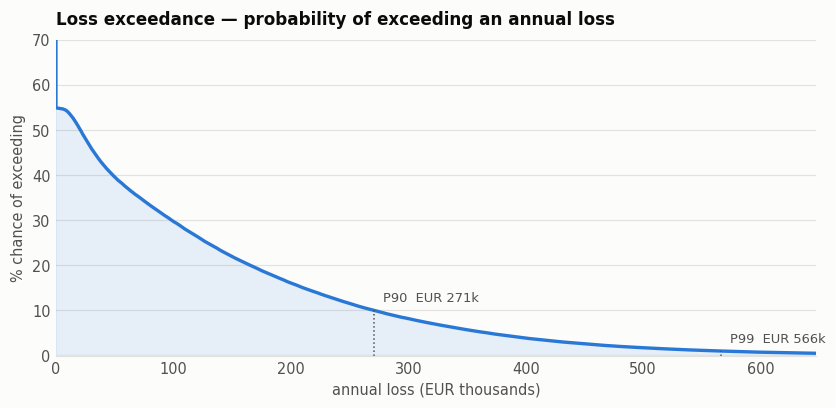

In [5]:
fig, ax = plt.subplots(figsize=(7.8, 3.8))
losses, probs = r.exceedance_curve(points=400)
ax.plot(losses / 1000, probs * 100, color=PALETTE["blue"], lw=2.2)
ax.fill_between(losses / 1000, probs * 100, color=PALETTE["blue"], alpha=.10)
for q, label in ((90, "P90"), (99, "P99")):
    x = r.percentile(q) / 1000
    ax.plot([x, x], [0, 100 - q], color=INK_MUTED, lw=1, ls=":")
    ax.annotate(f"{label}  EUR {x:,.0f}k", (x, 100 - q), xytext=(6, 6),
                textcoords="offset points", color=INK_MUTED, fontsize=8.5)
ax.set_title("Loss exceedance — probability of exceeding an annual loss")
ax.set_xlabel("annual loss (EUR thousands)"); ax.set_ylabel("% chance of exceeding")
ax.set_xlim(0, r.percentile(99.5) / 1000); ax.set_ylim(0, 70)
despine(ax); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

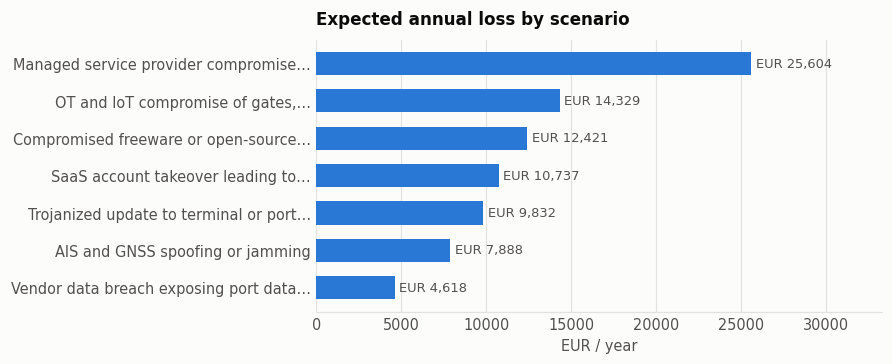

In [6]:
ales = sorted(((short(NAMES[s.id], 38), scenario_ale(s)) for s in derived),
              key=lambda kv: kv[1])
fig, ax = plt.subplots(figsize=(8.2, 3.4))
bars = ax.barh([k for k, _ in ales], [v for _, v in ales],
               color=PALETTE["blue"], height=0.62)
label_bars(ax, bars, [v for _, v in ales], "EUR {:,.0f}", horizontal=True)
ax.set_title("Expected annual loss by scenario")
ax.set_xlabel("EUR / year")
ax.set_xlim(0, max(v for _, v in ales) * 1.3)
despine(ax); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

## A result the derivation produced, and intuition would not

With the placeholder hourly cost, MSP ransomware ranked first. Once the hourly figure
was *derived* — €659, because a small port's revenue per hour is genuinely modest —
the ordering changed: downtime-driven scenarios carry less weight than a direct,
unrecoverable cash loss.

A qualitative heat map would almost certainly have marked ransomware *critical* and
business email compromise *medium*. That reversal is the clearest argument in this
project for quantifying rather than colouring.